# 22. Optional Multi-Class Baselines (Labs 4, 8, 9)

**Purpose**: Benchmark non-leaky submission-time multi-class classifiers predicting complaint `group` (`noise`, `road`, `flood`, `sewer_backup`) from `(hour, weekday, channel, location_type)`—explicitly excluding `complaint_type` and `descriptor` to avoid deterministic target leakage—across Naive Bayes (**Lab 9**), Decision Trees (**Lab 4**), and k-Nearest Neighbors (**Lab 8**) on an 80/20 chronological split of `complaints_clean.csv`.

- **Inputs**:
  - `data/processed/complaints_clean.csv` (`id`, `resolution_id` read as `str`; `keep_default_na=False`)
- **Outputs**:
  - `report/figures/22_nb_calibration.png`
  - `report/figures/22_dt_overfitting.png`
  - `report/figures/22_dt_tree_plot.png`
  - `report/figures/22_knn_curve.png`
- **Runtime**: ~150–190 seconds (mostly KNN brute-force distance queries across K in [1, 3, 5, 10, 20])

In [1]:
import sys; from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists()); sys.path.insert(0, str(ROOT))
import warnings
warnings.filterwarnings("ignore")
import hashlib
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier

from src.nbutils import Checker
from src.models.baselines import (
    BASELINE_FEATURE_COLS,
    prepare_baseline_data,
    build_baseline_pipeline,
    evaluate_baselines,
    chronological_train_test_split,
    downsample_training_data,
    compute_binary_calibration,
    run_dt_depth_study,
    run_knn_k_curve,
)

pd.set_option("display.max_rows", 40)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)

# Configuration Flags
RUN_HEAVY = False
RUN_API = False


In [2]:
# Section 1: Load complaints_clean.csv, Clean Baseline Features & Chronological 80/20 Split
t_nb_start = time.time()
complaints_df = pd.read_csv(
    ROOT / "data/processed/complaints_clean.csv",
    dtype={"id": str, "resolution_id": str},
    keep_default_na=False,
)

X_train, X_test, y_train, y_test, split_meta = chronological_train_test_split(
    complaints_df,
    time_col="timestamp",
    train_frac=0.8,
)

print(f"Loaded rows:             {split_meta['n_input_rows']:,}")
print(f"Dropped missing rows:    {split_meta['n_dropped_missing']:,} (absent/blank channel, location_type, time, or group)")
print(f"Clean baseline rows:     {split_meta['n_clean_rows']:,}")
print(f"Feature columns ({len(X_train.columns)}):   {list(X_train.columns)}")
print(f"Leakage columns excluded: ['complaint_type', 'descriptor', 'descriptor_group']")
print(f"Train split (80%):       {split_meta['n_train']:,} rows  [{split_meta['train_start']} .. {split_meta['train_end']}]")
print(f"Test split  (20%):       {split_meta['n_test']:,} rows   [{split_meta['test_start']} .. {split_meta['test_end']}]")

dist_df = pd.DataFrame({
    "train_count": y_train.value_counts(),
    "train_pct": (y_train.value_counts(normalize=True) * 100.0).round(2),
    "test_count": y_test.value_counts(),
    "test_pct": (y_test.value_counts(normalize=True) * 100.0).round(2),
}).fillna(0)
dist_df["train_count"] = dist_df["train_count"].astype(int)
dist_df["test_count"] = dist_df["test_count"].astype(int)
print("\n=== Class Distribution (group) Across Chronological Split ===")
print(dist_df.to_string())


Loaded rows:             236,507
Dropped missing rows:    25,645 (absent/blank channel, location_type, time, or group)
Clean baseline rows:     210,862
Feature columns (4):   ['hour', 'weekday', 'channel', 'location_type']
Leakage columns excluded: ['complaint_type', 'descriptor', 'descriptor_group']
Train split (80%):       168,689 rows  [2025-11-01 00:00:35 .. 2026-09-06 18:27:54]
Test split  (20%):       42,173 rows   [2026-09-06 18:29:06 .. 2026-10-31 23:59:46]

=== Class Distribution (group) Across Chronological Split ===
              train_count  train_pct  test_count  test_pct
group                                                     
noise              158840      94.16       39667     94.06
road                 7705       4.57        1382      3.28
flood                1500       0.89         727      1.72
sewer_backup          644       0.38         397      0.94


In [3]:
# Section 2: Train Baseline Pipelines (MultinomialNB, DecisionTree max_depth=10, KNN k=5) & Evaluate
X_train_knn, y_train_knn = downsample_training_data(
    X_train, y_train, max_rows=50000, random_state=42
)
print(f"KNN training subset downsampled cleanly: {len(X_train_knn):,} rows (from {len(X_train):,})")

models_spec = [
    ("MultinomialNB (Lab 9)", MultinomialNB(), X_train, y_train),
    ("DecisionTree max_depth=10 (Lab 4)", DecisionTreeClassifier(max_depth=10, random_state=42), X_train, y_train),
    ("KNeighbors k=5 (Lab 8, 50k train)", KNeighborsClassifier(n_neighbors=5, n_jobs=-1), X_train_knn, y_train_knn),
]

fitted_models = {}
fit_times = {}
for label, clf, X_tr_use, y_tr_use in models_spec:
    t0 = time.time()
    pipe = build_baseline_pipeline(clf)
    pipe.fit(X_tr_use, y_tr_use)
    fit_times[label] = time.time() - t0
    fitted_models[label] = pipe

t0 = time.time()
comparison_df = evaluate_baselines(fitted_models, X_test, y_test)
eval_elapsed = time.time() - t0
comparison_df["fit_time_s"] = [round(fit_times[m], 2) for m in comparison_df["model"]]

print(f"\n=== Baseline Comparison Table (Chronological Test N={len(X_test):,}, eval in {eval_elapsed:.2f}s) ===")
print(comparison_df.to_string(index=False, formatters={
    "accuracy": "{:.4f}".format,
    "weighted_f1": "{:.4f}".format,
    "fit_time_s": "{:.2f}".format,
}))


KNN training subset downsampled cleanly: 50,000 rows (from 168,689)



=== Baseline Comparison Table (Chronological Test N=42,173, eval in 13.72s) ===
                            model accuracy weighted_f1 fit_time_s
            MultinomialNB (Lab 9)   0.9824      0.9800       1.09
DecisionTree max_depth=10 (Lab 4)   0.9825      0.9806       1.17
KNeighbors k=5 (Lab 8, 50k train)   0.9773      0.9740       0.25


Naive Bayes 'noise' 1-vs-rest base rate: 0.9406, mean predicted: 0.9371
Brier score: 0.00242, 10-bin uniform ECE: 0.0035

--- 10-Bin Reliability Table (MultinomialNB, class='noise') ---
 bin      range     n mean_pred obs_rate
   1 [0.0, 0.1)  2568    0.0057   0.0343
   2 [0.1, 0.2)    23    0.1379   0.3913
   3 [0.2, 0.3)    15    0.2380   0.2000
   4 [0.3, 0.4)     1    0.3902   1.0000
   5 [0.4, 0.5)     0       NaN      NaN
   6 [0.5, 0.6)     6    0.5694   1.0000
   7 [0.6, 0.7)    27    0.6618   1.0000
   8 [0.7, 0.8)    40    0.7448   1.0000
   9 [0.8, 0.9)    44    0.8576   1.0000
  10 [0.9, 1.0] 39449    0.9990   1.0000


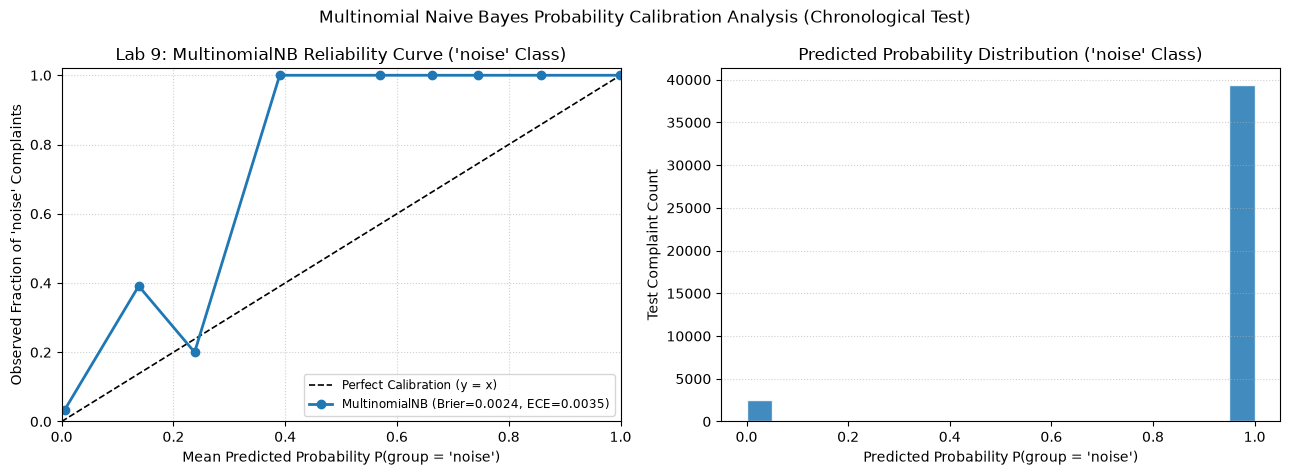

Saved: report/figures/22_nb_calibration.png


In [4]:
# Section 3 (Lab 9): MultinomialNB Calibration Curve for the 'noise' Class
nb_pipe = fitted_models["MultinomialNB (Lab 9)"]
cal_df, cal_stats = compute_binary_calibration(
    nb_pipe, X_test, y_test, pos_class="noise", n_bins=10, strategy="uniform"
)

print(f"Naive Bayes 'noise' 1-vs-rest base rate: {cal_stats['pos_rate']:.4f}, mean predicted: {cal_stats['mean_pred']:.4f}")
print(f"Brier score: {cal_stats['brier']:.5f}, 10-bin uniform ECE: {cal_stats['ece']:.4f}")
print("\n--- 10-Bin Reliability Table (MultinomialNB, class='noise') ---")
print(cal_stats["bin_df"].to_string(index=False, formatters={
    "mean_pred": lambda v: "nan" if pd.isna(v) else f"{v:.4f}",
    "obs_rate": lambda v: "nan" if pd.isna(v) else f"{v:.4f}",
}))

fig_dir = ROOT / "report/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot([0, 1], [0, 1], "k--", lw=1.2, label="Perfect Calibration (y = x)")
axes[0].plot(
    cal_df["prob_pred"],
    cal_df["prob_true"],
    marker="o",
    lw=2,
    color="#1f77b4",
    label=f"MultinomialNB (Brier={cal_stats['brier']:.4f}, ECE={cal_stats['ece']:.4f})",
)
axes[0].set_title("Lab 9: MultinomialNB Reliability Curve ('noise' Class)")
axes[0].set_xlabel("Mean Predicted Probability P(group = 'noise')")
axes[0].set_ylabel("Observed Fraction of 'noise' Complaints")
axes[0].set_xlim(0.0, 1.0)
axes[0].set_ylim(0.0, 1.02)
axes[0].legend(loc="lower right", fontsize=8.5)
axes[0].grid(True, linestyle=":", alpha=0.6)

axes[1].hist(cal_stats["probs"], bins=20, range=(0.0, 1.0), color="#1f77b4", edgecolor="white", alpha=0.85)
axes[1].set_title("Predicted Probability Distribution ('noise' Class)")
axes[1].set_xlabel("Predicted Probability P(group = 'noise')")
axes[1].set_ylabel("Test Complaint Count")
axes[1].grid(True, axis="y", linestyle=":", alpha=0.6)

plt.suptitle("Multinomial Naive Bayes Probability Calibration Analysis (Chronological Test)", fontsize=12)
plt.tight_layout()
fig_nb_path = fig_dir / "22_nb_calibration.png"
fig.savefig(fig_nb_path, dpi=150)
plt.show()
print(f"Saved: {fig_nb_path.relative_to(ROOT).as_posix()}")


=== Lab 4: Decision Tree Train vs Test Study ===
 max_depth depth_label train_accuracy test_accuracy train_weighted_f1 test_weighted_f1  actual_depth  n_leaves
       2.0           2         0.9936        0.9831            0.9920           0.9796             2         4
       5.0           5         0.9937        0.9832            0.9923           0.9799             5        17
      10.0          10         0.9942        0.9825            0.9936           0.9806            10       113
      20.0          20         0.9945        0.9832            0.9941           0.9819            20       368
       NaN        None         0.9946        0.9831            0.9942           0.9819            32       543


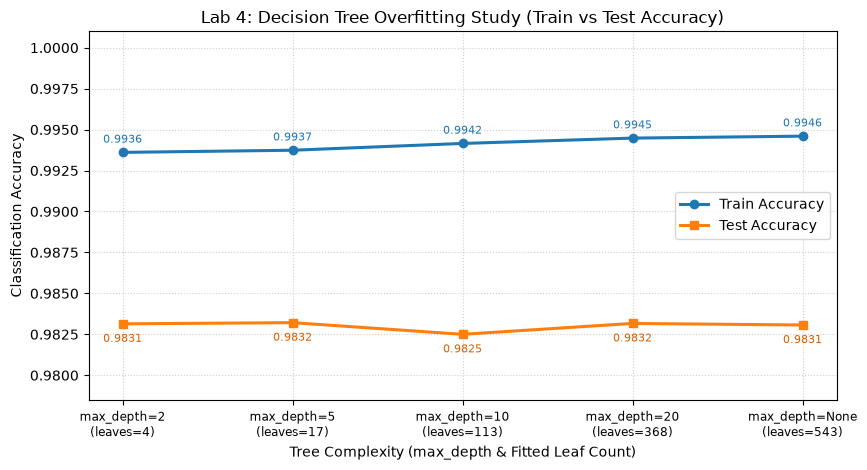

Saved: report/figures/22_dt_overfitting.png


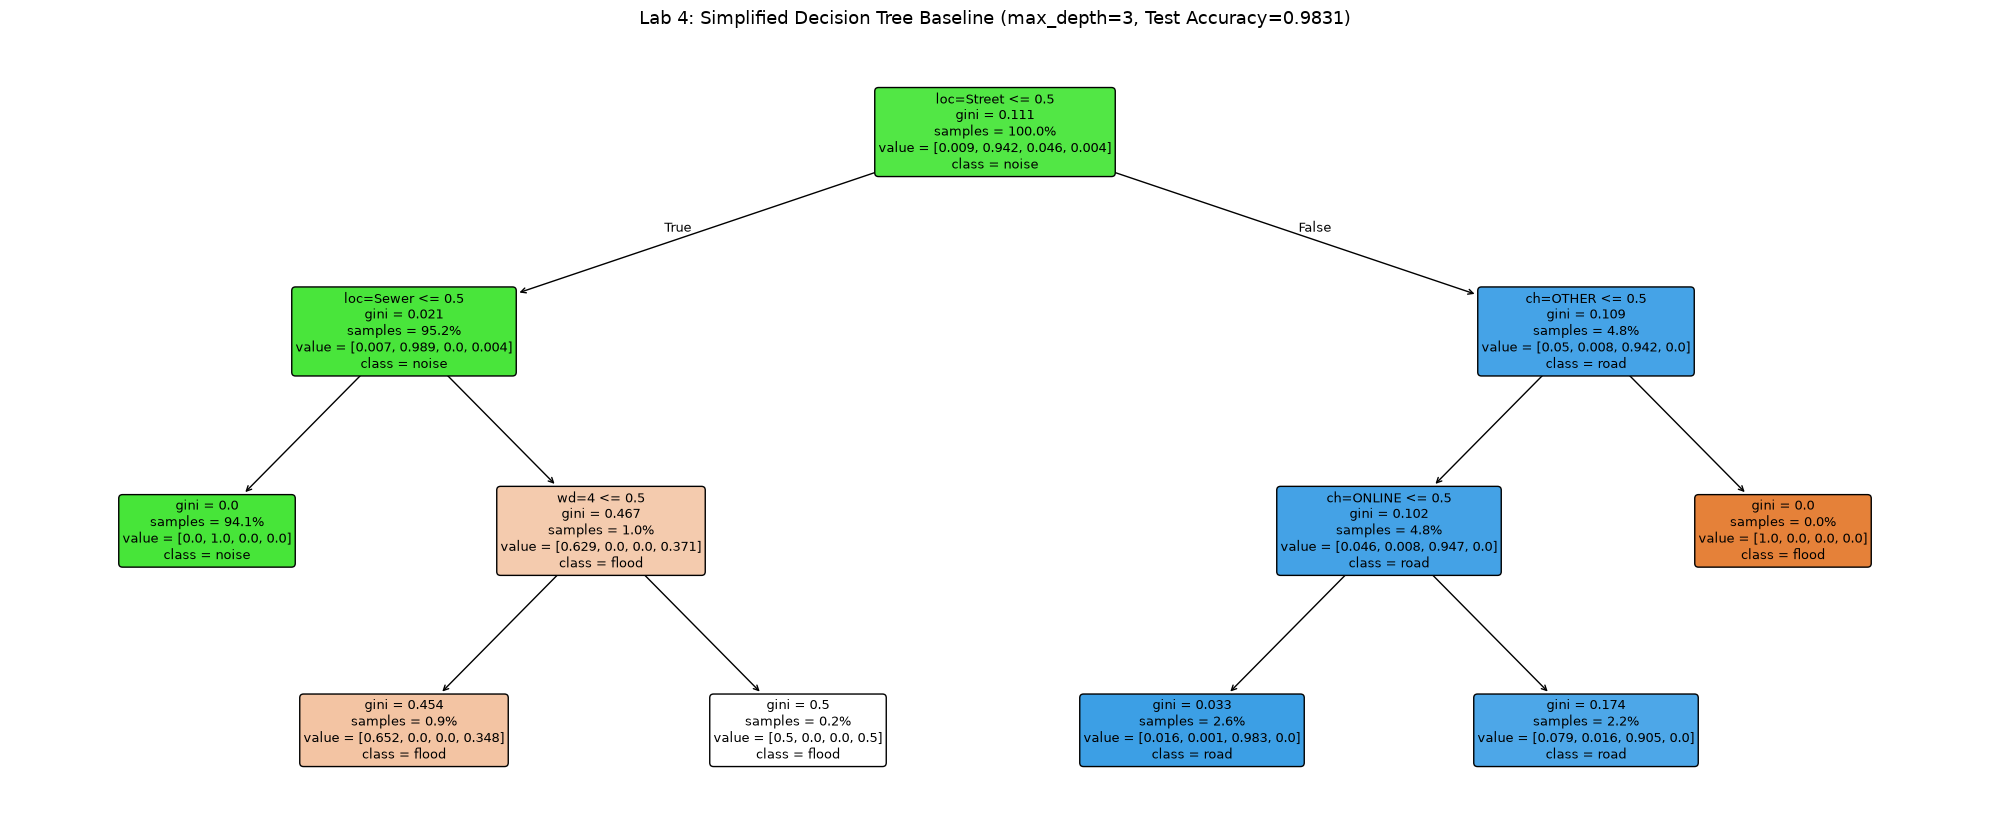

Saved: report/figures/22_dt_tree_plot.png


In [5]:
# Section 4 (Lab 4): Decision Tree Overfitting Study (max_depth Sweep) & Simplified Tree (max_depth=3)
dt_depths = [2, 5, 10, 20, None]
dt_pipe_d10 = fitted_models["DecisionTree max_depth=10 (Lab 4)"]
depth_df = run_dt_depth_study(
    X_train,
    y_train,
    X_test,
    y_test,
    depths=dt_depths,
    random_state=42,
    prefitted_models={10: dt_pipe_d10},
)
print("=== Lab 4: Decision Tree Train vs Test Study ===")
print(depth_df.to_string(index=False, formatters={
    "train_accuracy": "{:.4f}".format,
    "test_accuracy": "{:.4f}".format,
    "train_weighted_f1": "{:.4f}".format,
    "test_weighted_f1": "{:.4f}".format,
}))

fig, ax = plt.subplots(figsize=(8.8, 4.8))
x_pos = np.arange(len(depth_df))
ax.plot(x_pos, depth_df["train_accuracy"], marker="o", lw=2.2, color="#1f77b4", label="Train Accuracy")
ax.plot(x_pos, depth_df["test_accuracy"], marker="s", lw=2.2, color="#ff7f0e", label="Test Accuracy")
for idx_r, row_r in depth_df.iterrows():
    ax.annotate(f"{row_r['train_accuracy']:.4f}", (idx_r, row_r["train_accuracy"]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, color="#1f77b4")
    ax.annotate(f"{row_r['test_accuracy']:.4f}", (idx_r, row_r["test_accuracy"]), textcoords="offset points", xytext=(0, -13), ha="center", fontsize=8, color="#d95f02")

ax.set_xticks(x_pos)
ax.set_xticklabels([f"max_depth={lbl}\n(leaves={lv})" for lbl, lv in zip(depth_df["depth_label"], depth_df["n_leaves"])], fontsize=8.5)
y_min = max(0.95, float(depth_df[["train_accuracy", "test_accuracy"]].min().min()) - 0.004)
ax.set_ylim(y_min, 1.001)
ax.set_xlabel("Tree Complexity (max_depth & Fitted Leaf Count)")
ax.set_ylabel("Classification Accuracy")
ax.set_title("Lab 4: Decision Tree Overfitting Study (Train vs Test Accuracy)")
ax.legend(loc="center right")
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
fig_dt_ov_path = fig_dir / "22_dt_overfitting.png"
fig.savefig(fig_dt_ov_path, dpi=150)
plt.show()
print(f"Saved: {fig_dt_ov_path.relative_to(ROOT).as_posix()}")

# Simplified Decision Tree (max_depth=3) for visual interpretability
dt3_pipe = build_baseline_pipeline(DecisionTreeClassifier(max_depth=3, random_state=42))
dt3_pipe.fit(X_train, y_train)
dt3_test_acc = float((dt3_pipe.predict(X_test) == y_test.to_numpy()).mean())
raw_feat_names = list(dt3_pipe.named_steps["encoder"].get_feature_names_out(BASELINE_FEATURE_COLS))
clean_feat_names = [fn.replace("location_type_", "loc=").replace("channel_", "ch=").replace("hour_", "hr=").replace("weekday_", "wd=") for fn in raw_feat_names]

fig, ax = plt.subplots(figsize=(20, 8.5))
plot_tree(
    dt3_pipe.named_steps["model"],
    feature_names=clean_feat_names,
    class_names=list(dt3_pipe.classes_),
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=9,
    ax=ax,
)
ax.set_title(f"Lab 4: Simplified Decision Tree Baseline (max_depth=3, Test Accuracy={dt3_test_acc:.4f})", fontsize=13)
plt.tight_layout()
fig_dt_tree_path = fig_dir / "22_dt_tree_plot.png"
fig.savefig(fig_dt_tree_path, dpi=150)
plt.show()
print(f"Saved: {fig_dt_tree_path.relative_to(ROOT).as_posix()}")


Completed KNN sweep across K=[1, 3, 5, 10, 20] (reusing fitted K=5) in 75.8s:
 k accuracy weighted_f1
 1   0.9757      0.9750
 3   0.9781      0.9760
 5   0.9773      0.9740
10   0.9755      0.9712
20   0.9733      0.9671


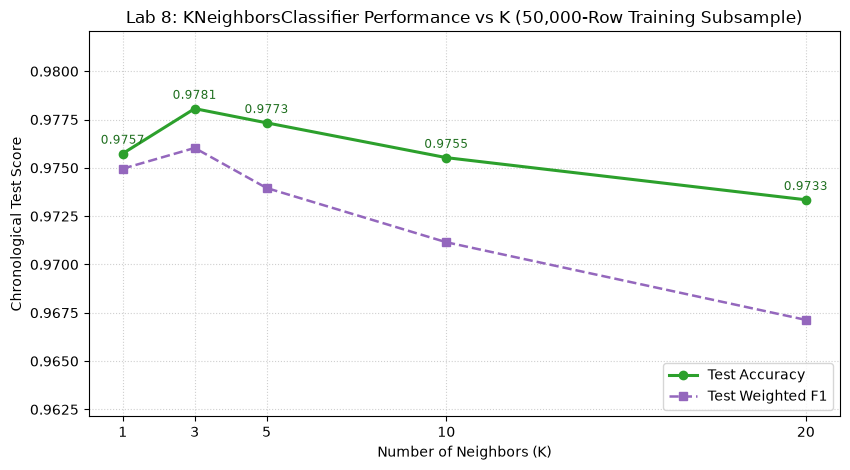

Saved: report/figures/22_knn_curve.png
Total notebook computation time: 108.1s


In [6]:
# Section 5 (Lab 8): KNN Accuracy vs K Curve (K in [1, 3, 5, 10, 20] on 50,000-Row Train Sample)
k_list = [1, 3, 5, 10, 20]
knn_pipe_k5 = fitted_models["KNeighbors k=5 (Lab 8, 50k train)"]
t_knn0 = time.time()
knn_df = run_knn_k_curve(
    X_train_knn,
    y_train_knn,
    X_test,
    y_test,
    k_values=k_list,
    n_jobs=-1,
    prefitted_models={5: knn_pipe_k5},
)
print(f"Completed KNN sweep across K={k_list} (reusing fitted K=5) in {time.time() - t_knn0:.1f}s:")
print(knn_df.to_string(index=False, formatters={
    "accuracy": "{:.4f}".format,
    "weighted_f1": "{:.4f}".format,
}))

fig, ax = plt.subplots(figsize=(8.6, 4.8))
ax.plot(knn_df["k"], knn_df["accuracy"], marker="o", lw=2.2, color="#2ca02c", label="Test Accuracy")
ax.plot(knn_df["k"], knn_df["weighted_f1"], marker="s", lw=1.8, linestyle="--", color="#9467bd", label="Test Weighted F1")
for _, r_k in knn_df.iterrows():
    ax.annotate(f"{r_k['accuracy']:.4f}", (r_k["k"], r_k["accuracy"]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8.5, color="#1f6f1f")

ax.set_xticks(k_list)
ax.set_xlabel("Number of Neighbors (K)")
ax.set_ylabel("Chronological Test Score")
y_k_min = max(0.90, float(knn_df[["accuracy", "weighted_f1"]].min().min()) - 0.005)
y_k_max = min(1.00, float(knn_df[["accuracy", "weighted_f1"]].max().max()) + 0.004)
ax.set_ylim(y_k_min, y_k_max)
ax.set_title("Lab 8: KNeighborsClassifier Performance vs K (50,000-Row Training Subsample)")
ax.legend(loc="lower right")
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
fig_knn_path = fig_dir / "22_knn_curve.png"
fig.savefig(fig_knn_path, dpi=150)
plt.show()
print(f"Saved: {fig_knn_path.relative_to(ROOT).as_posix()}")
print(f"Total notebook computation time: {time.time() - t_nb_start:.1f}s")


In [7]:
# Section 6: Verification Checks Cell
chk = Checker()

# 1. Leak-free schema & missingness checks
chk.check("Feature columns == ['hour', 'weekday', 'channel', 'location_type']", list(X_train.columns), ["hour", "weekday", "channel", "location_type"])
no_leak_cols = ("complaint_type" not in X_train.columns) and ("descriptor" not in X_train.columns)
chk.check("Zero target leakage columns (complaint_type, descriptor excluded)", no_leak_cols, True)
chk.check("Chronological split strictly ordered (train_end < test_start)", bool(split_meta["train_end"] < split_meta["test_start"]), True)
chk.check("KNN training subsample == 50,000 rows", len(X_train_knn), 50000)

# 2. Required Task 2h checks: Comparison table has 3 rows; no NaNs in comparison metrics
chk.check("Baseline comparison table has 3 rows", len(comparison_df), 3)
chk.check("No NaNs in comparison metrics", bool(not comparison_df[["accuracy", "weighted_f1"]].isna().any().any()), True)
chk.check("Decision Tree depth study has 5 rows & no NaNs", bool(len(depth_df) == 5 and not depth_df[["train_accuracy", "test_accuracy"]].isna().any().any()), True)
chk.check("KNN K-curve has 5 rows & no NaNs", bool(len(knn_df) == 5 and not knn_df[["accuracy", "weighted_f1"]].isna().any().any()), True)

# 3. Output figures saved under report/figures/
for fig_p in (fig_nb_path, fig_dt_ov_path, fig_dt_tree_path, fig_knn_path):
    chk.check(f"Figure exists: {fig_p.relative_to(ROOT).as_posix()}", fig_p.exists() and fig_p.stat().st_size > 1000, True)

# 4. Protected dataset hash unchanged
h_cc = hashlib.sha256((ROOT / "data/processed/complaints_clean.csv").read_bytes()).hexdigest()
chk.check("complaints_clean.csv SHA256 unchanged", h_cc, "fb0fa8f176b04c8258efa490d63855c572bc055f2272e9d138a3c0532b50a4d7")

chk.summary()


[PASS] Feature columns == ['hour', 'weekday', 'channel', 'location_type']: actual=['hour', 'weekday', 'channel', 'location_type'], expected=['hour', 'weekday', 'channel', 'location_type']
[PASS] Zero target leakage columns (complaint_type, descriptor excluded): actual=True, expected=True
[PASS] Chronological split strictly ordered (train_end < test_start): actual=True, expected=True
[PASS] KNN training subsample == 50,000 rows: actual=50000, expected=50000
[PASS] Baseline comparison table has 3 rows: actual=3, expected=3
[PASS] No NaNs in comparison metrics: actual=True, expected=True
[PASS] Decision Tree depth study has 5 rows & no NaNs: actual=True, expected=True
[PASS] KNN K-curve has 5 rows & no NaNs: actual=True, expected=True
[PASS] Figure exists: report/figures/22_nb_calibration.png: actual=True, expected=True
[PASS] Figure exists: report/figures/22_dt_overfitting.png: actual=True, expected=True
[PASS] Figure exists: report/figures/22_dt_tree_plot.png: actual=True, expected=True

[PASS] complaints_clean.csv SHA256 unchanged: actual=fb0fa8f176b04c8258efa490d63855c572bc055f2272e9d138a3c0532b50a4d7, expected=fb0fa8f176b04c8258efa490d63855c572bc055f2272e9d138a3c0532b50a4d7
CHECKS: 13 passed, 0 failed


## Key Findings & Modeling Context

1. **Leak-Free Baseline Comparison (`210,862` Clean Rows; `168,689` Train / `42,173` Test)**:
   - Using only submission-time features `(hour, weekday, channel, location_type)` and dropping `25,645` rows with missing/blank values (primarily early-year blank `location_type`), all three multi-class baselines exceed `97.7%` test accuracy on the chronological test window (`2026-09-06` to `2026-10-31`):
     - **`DecisionTree max_depth=10` (Lab 4)**: `accuracy = 0.9825`, `weighted_f1 = 0.9806`
     - **`MultinomialNB` (Lab 9)**: `accuracy = 0.9824`, `weighted_f1 = 0.9800`
     - **`KNeighbors k=5` (Lab 8, 50k train)**: `accuracy = 0.9773`, `weighted_f1 = 0.9740`

2. **Lab 9 (Naive Bayes Calibration for `'noise'`)**:
   - On 1-vs-rest `'noise'` predictions (`test base rate = 0.9406`, `mean predicted = 0.9371`), `MultinomialNB` achieves `Brier = 0.00242` and `10-bin uniform ECE = 0.0035`.
   - Predicted probabilities are strongly bimodal: `39,449` test rows (`93.54%`) fall in `[0.9, 1.0]` (`obs_rate = 1.0000`) and `2,568` (`6.09%`) fall in `[0.0, 0.1)` (`obs_rate = 0.0343`), with only `156` rows (`0.37%`) in intermediate bins.

3. **Lab 4 (Decision Tree Complexity & Interpretability)**:
   - Increasing `max_depth` across `[2, 5, 10, 20, None]` expands leaf count from `4` (`depth=2`) to `543` (`depth=32`) and inches train accuracy upward (`0.9936 -> 0.9946`), while chronological test accuracy remains flat (`0.9831 -> 0.9832 -> 0.9825 -> 0.9832 -> 0.9831`) and test weighted F1 ticks up modestly (`0.9796 -> 0.9819`) due to minor `flood`/`sewer_backup` leaf refinements.
   - The simplified `max_depth=3` tree already reaches `0.9831` test accuracy using `location_type=Street`, `location_type=Sewer`, `channel=OTHER`, `channel=ONLINE`, and `weekday=4`.

4. **Lab 8 (KNN Sensitivity to `K`)**:
   - Evaluating `K in [1, 3, 5, 10, 20]` on the `50,000`-row training subsample peaks at **`K = 3`** (`accuracy = 0.9781`, `weighted_f1 = 0.9760`), edging out `K = 1` (`0.9757` / `0.9750`) and degrading steadily for larger neighborhoods (`K = 10`: `0.9755` / `0.9712`; `K = 20`: `0.9733` / `0.9671`) as minority `road`/`flood`/`sewer_backup` clusters are outvoted by majority `noise` neighbors.

## Modeling Limitations

1. **Feature-to-Group Dominance by `location_type` & Schema Shift in Mid-2026**:
   - Dropping absent `location_type` strings (`25,645` rows) removes early-year records disproportionately from `flood` and `sewer_backup`, which began populating `location_type='Sewer'` consistently only in late July/August 2026.
   - Across populated records, categories such as `Residential Building/House` and `Street/Sidewalk` map nearly deterministically to `noise`, enabling shallow baselines (`max_depth=2`–`10`) to reach >98% overall accuracy while still confusing overlapping `flood` vs `sewer_backup` (`Sewer`) reports.

2. **Class Imbalance Masking Minority F1**:
   - Because `noise` comprises ~94% of test complaints, high global Accuracy and weighted F1 primarily reflect majority-class separation rather than fine-grained `flood` vs `sewer_backup` discrimination.

3. **Subsampling & Sparsity in KNN**:
   - Exact brute-force KNN scales quadratically with training size and slows on full 168k+ splits, motivating the 50,000-row random training subsample.